## Lufthansa Model


In [4]:
# Import necessary libraries
import pandas as pd
from datetime import timedelta, datetime
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, r2_score, make_scorer, f1_score,  roc_auc_score, classification_report
from sklearn import metrics

import statsmodels.api as sm
lowess = sm.nonparametric.lowess

In [5]:
# Load prepared dataset
loaded_data = pd.read_csv('airline_data/Lufthansa_data_2.csv')
print(loaded_data.columns)

Index(['itinerary_id', 'departure_date', 'region_from', 'region_to',
       'flight_number', 'airline_name', 'operator', 'aircraft', 'src', 'dst',
       'travel_time', 'seat_pitch_type', 'emissions', 'price',
       'days_to_departure', 'is_weekend', 'dep_dayofweek', 'dep_month',
       'dep_dayofyear', 'dep_dayofmonth', 'dep_year', 'season', 'dep_hour_bin',
       'arr_hour_bin', 'price_hour_bin'],
      dtype='object')


In [6]:
from sklearn.linear_model import LinearRegression
def price_will_go_down(df, stats_df,  sample_max = None, sample_min = None):    
    # Sort by flight_id and days_to_departure and set route_key
    df = df.sort_values(['itinerary_id', 'days_to_departure'], ascending=[True, False])
    df['route_key'] = df['src'].astype(str) + '_' + df['dst'].astype(str) + '_' + df['dep_month'].astype(str)


    stats_df = stats_df.copy()
    stats_df['route_key'] = (
        stats_df['src'].astype(str) + '_' + stats_df['dst'].astype(str) + '_' + stats_df['dep_month'].astype(str)
    )

    route_stats = (
        stats_df.groupby('route_key')['price']
                .agg(route_min_price=lambda x: x.quantile(0.15),
                    route_max_price=lambda x: x.quantile(0.85))
                .reset_index()
    )

    # Group by route_key to calculate route statistics
    if sample_max is None:
        df = df.merge(route_stats, on='route_key', how='left')
    else:
        print(f'Using provided sample_max: {sample_max}, sample_min: {sample_min}')
        df['route_max_price'] = sample_max
        df['route_min_price'] = sample_min

    # fallback for unseen routes (global TRAIN quantiles)
    global_min = stats_df['price'].quantile(0.15)
    global_max = stats_df['price'].quantile(0.85)
    df['route_min_price'] = df['route_min_price'].fillna(global_min)
    df['route_max_price'] = df['route_max_price'].fillna(global_max)



    # Relative/position features
    eps = 1e-9
    #df['price_vs_route_max'] = df['price'] / df['route_max_price'].replace(0, eps)
    df['price_range'] = df['route_max_price'] - df['route_min_price']
    print(df['price_range'])
    df['price_position'] = (df['price'] - df['route_min_price']) / df['price_range']
    df['price_position_x_days'] = df['price_position'] * df['days_to_departure']
    df['urgency_score'] = 1.0 / (df['days_to_departure'] + 1.0)

    # Trend slope feature using gradient     


    def roll(g, clip_change=0.5):
        g = g.sort_values('days_to_departure', ascending=False).copy()
        # past-only base
        p = g["price"]
        p1 = p.shift(1)           # t-1
        p3 = p.shift(3)           # t-3

        # rollings on past-only price
        g["roll_min_7"] = p1.rolling(7, min_periods=1).min()
        g["roll_max_7"] = p1.rolling(7, min_periods=1).max()
        g['roll_range_7'] = g['roll_max_7'] - g['roll_min_7']
        g["roll_std_7"] = p1.rolling(7, min_periods=2).std()
        g["roll_mean_3"] = p1.rolling(3, min_periods=1).mean()   # optional but useful

        # lags
        g["lag1"] = p1
        g["lag3"] = p3

        # percent changes (safe divide + clip extremes)
        eps = 1e-9
        g["chg_1"] = ((p - p1) / (p1.replace(0, eps))).clip(-clip_change, clip_change)
        g["chg_3"] = ((p - p3) / (p3.replace(0, eps))).clip(-clip_change, clip_change)

        # count increases in last 5 steps (past-only)
        # use min_periods=1 so early rows aren’t NaN, then cast to Int16
        g["inc_count_5"] = (p.diff(1) > 0).rolling(5, min_periods=1).sum().astype("Int16")

        # tidy up any initial NaNs from shifts/rolls
        for col in ["roll_std_7", "lag3", "chg_1", "chg_3"]:
            g[col] = g[col].fillna(0)

        g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))


        return g
    
        
    def should_wait(row):

        if pd.isna(row['min_future_price']):
            return 0
        
        min_abs_savings = 5  # Minimum absolute savings to consider waiting

        days = row['days_to_departure']
        current_price = row['price']
        min_future_price = row['min_future_price']
        abs_savings = current_price - min_future_price
        savings_ratio = (row['price'] - row['min_future_price']) / row['price']

        # If price is significantly lower than min_price there is no point in waiting
        if row['price_position'] < -0.1:
            return 0
        if abs_savings < min_abs_savings:
            return 0

        if 3 <= days <= 7:
            return int(savings_ratio > 0.15 and row['price'] > row['min_future_price'] * 1.15)
        if 8 <= days <= 20:
            return int(savings_ratio > 0.10 and row['price'] > row['min_future_price'] * 1.10)
        if days >= 21:
            return int(savings_ratio > 0.05 and row['price'] > row['min_future_price'] * 1.05)
        return 0
    
    # --- Future Price Calculation ---
    df['min_future_price'] = df.groupby('itinerary_id')['price'].transform(
        lambda x: x[::-1].cummin().shift(1)[::-1]
    )
    df['label'] = df.apply(should_wait, axis=1)
    
    df = df.groupby('itinerary_id').apply(roll).reset_index(drop=True)


    
    def rolling_trend_slope(x, window=5):
        X = np.arange(len(x)).reshape(-1,1)
        reg = LinearRegression().fit(X, x)
        return reg.coef_[0] 

    #df['trend_slope_5'] = df['price'].shift(1).rolling(5).apply(rolling_trend_slope, raw=True)

    # --- Clean-up ---
    df = df.dropna(subset=['min_future_price', 'roll_min_7', 'roll_max_7', 'roll_std_7', 'lag3', 'chg_1', 'chg_3', 'inc_count_5'])  # final price can't be predicted

    df = df.drop_duplicates(subset=['itinerary_id', 'days_to_departure'], keep='last')

    return df

In [7]:
def encode_categorical_features(data: pd.DataFrame, categorical_cols: list) -> tuple[pd.DataFrame, dict]:
    """
    Encode categorical features using Label Encoding.
    
    :param data: DataFrame with data
    :param categorical_cols: List of categorical column names
    :return: Tuple of (encoded_data, encoders)
    """
    encoders = {}
    for col in categorical_cols:
        le = LabelEncoder()
        data[col] = le.fit_transform(data[col].astype(str))
        encoders[col] = le
    return data, encoders


def split_by_itinerary(data: pd.DataFrame, train_ratio: float = 0.8) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Split data by itinerary_id to ensure no data leakage.
    
    :param data: DataFrame to split
    :param train_ratio: Ratio of itineraries for training
    :return: Tuple of (train_data, test_data)
    """
    unique_itineraries = data['itinerary_id'].unique()
    train_size = int(train_ratio * len(unique_itineraries))
    
    train_itineraries = unique_itineraries[:train_size]
    
    train_data = data[data['itinerary_id'].isin(train_itineraries)]
    test_data = data[~data['itinerary_id'].isin(train_itineraries)]
    
    return train_data, test_data


def prepare_features_and_target(data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.Series]:
    """
    Prepare features (X) and target (y) by dropping unnecessary columns.
    
    :param data: DataFrame with all data
    :param target: Target column name
    :return: Tuple of (features, target)
    """

    
    data = data.loc[: ,['label', 'price', 'roll_std_7', 'lag1','lag3', 'chg_1', 'chg_3', 'inc_count_5', 'trend_slope', 'days_to_departure', 'dep_month', 'dep_dayofyear', 'region_from', 'region_to',
                        'price_position', 'price_position_x_days', 
                        'urgency_score',],]
    data = data.dropna()

    data.replace([np.inf, -np.inf], np.nan, inplace=True)
    data.dropna(inplace=True)

    X = data.drop(target, axis=1)
    y = data[target]
    
    return X, y


def prepare_data(loaded_data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series, pd.DataFrame, pd.Series, dict]:
    """
    Main function to prepare data for machine learning.
    
    :param loaded_data: Raw DataFrame
    :param target: Target column name
    :return: Tuple of (X, y, X_train, y_train, X_test, y_test, encoders)
    """
    data = loaded_data.copy()
    print(f"Initial data shape: {data.shape}")
    # Define categorical columns
    categorical_cols = [
        'region_from', 'region_to']

    # Step 1: Split by itinerary to avoid data leakage
    train_data, test_data = split_by_itinerary(data, train_ratio=0.8)

    # Step 2: Apply feature engineering to training and test data
    train_data = price_will_go_down(train_data, train_data)
    test_data = price_will_go_down(test_data, train_data)

    # Step 2: Encode categorical variables
    train_data, encoders = encode_categorical_features(train_data, categorical_cols)
    test_data, _ = encode_categorical_features(test_data, categorical_cols)

    # Step 3: Prepare features and target for full dataset
    X_train, y_train = prepare_features_and_target(train_data, target)
    X_test, y_test = prepare_features_and_target(test_data, target)

    return X_train, y_train, X_test, y_test, encoders, train_data


In [8]:
X_train, y_train, X_test, y_test, encoders, train_data = prepare_data(loaded_data,  'label')


print(f"Training data shape: {X_train.shape}, {y_train.shape}")
print(f"Test data shape: {X_test.shape}, {y_test.shape}")

# combine for eda
train = pd.concat([X_train, y_train], axis=1)
test = pd.concat([X_test, y_test], axis=1)
data = pd.concat([train, test], axis=0)



Initial data shape: (119691, 25)
0        313.0
1        313.0
2        313.0
3        313.0
4        313.0
         ...  
96242     94.0
96243     94.0
96244     94.0
96245     94.0
96246     94.0
Name: price_range, Length: 96247, dtype: float64


C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future

0        253.0
1        253.0
2        253.0
3        253.0
4        253.0
         ...  
23439     94.0
23440     94.0
23441     94.0
23442     94.0
23443     94.0
Name: price_range, Length: 23444, dtype: float64


C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future

Training data shape: (88722, 16), (88722,)
Test data shape: (21570, 16), (21570,)


C:\Users\pinyc\AppData\Local\Temp\ipykernel_12568\4138027230.py:118: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('itinerary_id').apply(roll).reset_index(drop=True)


## EDA

AttributeError: Can only use .dt accessor with datetimelike values

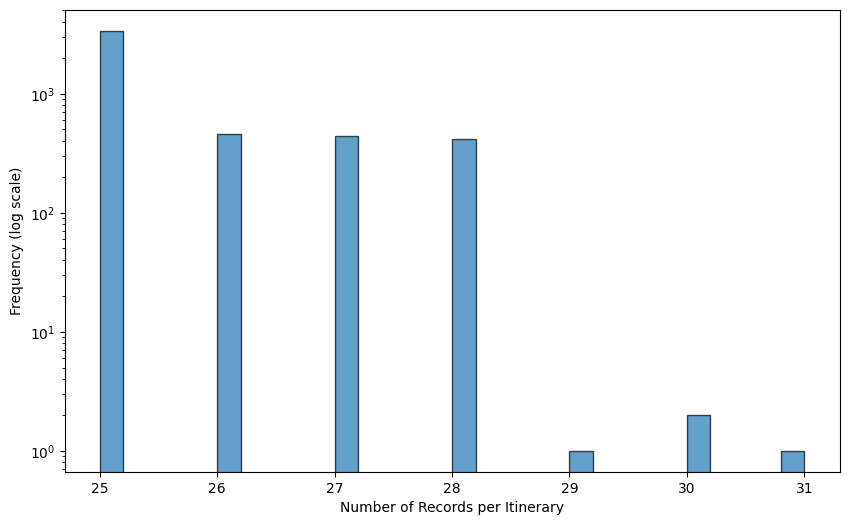

In [ ]:
# check number of records per itinerary, 

records_per_itinerary = loaded_data.groupby('itinerary_id').size()

plt.figure(figsize=(10,6))
plt.hist(records_per_itinerary, bins=30, edgecolor='k', alpha=0.7)
plt.yscale('log')
plt.xlabel('Number of Records per Itinerary')
plt.ylabel('Frequency (log scale)')

# check gaps between the days of departure



In [6]:
print(X_train.head())

    price  trend_slope_5  roll_std_7    lag1    lag3     chg_1     chg_3  \
5  160.82            6.4   14.310835  160.82  128.82  0.000000  0.248409   
6  160.82            9.6   16.524729  160.82  128.82  0.000000  0.248409   
7  160.82            9.6   17.104719  160.82  160.82  0.000000  0.000000   
8  160.82            6.4   17.104719  160.82  160.82  0.000000  0.000000   
9  184.82            0.0   15.614401  160.82  160.82  0.149235  0.149235   

   inc_count_5  trend_slope  days_to_departure  dep_month  dep_dayofyear  \
5            1          0.0                 26          8            220   
6            1          0.0                 24          8            220   
7            1          0.0                 22          8            220   
8            1         12.0                 20          8            220   
9            1         12.0                 18          8            220   

   region_from  region_to  price_position  price_position_x_days  \
5            7    

In [95]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif_safe(df, features=None, drop_constant=True, drop_duplicates=True, verbose=True):
    """
    Compute VIF on a clean, numeric float64 design matrix.
    - Casts all selected columns to float64
    - Drops columns with any non-finite values
    - Optionally drops constant and duplicate columns
    """
    if features is None:
        features = df.columns.tolist()

    X = df[features].copy()

    # 1) Coerce booleans to int
    for c in X.columns:
        if pd.api.types.is_bool_dtype(X[c]):
            X[c] = X[c].astype(np.int8)

    # 2) Keep only numeric dtypes
    X = X.select_dtypes(include=[np.number]).copy()

    # 3) Replace +/-inf and drop rows with NaNs
    X = X.replace([np.inf, -np.inf], np.nan).dropna(axis=0, how="any")

    # 4) Force float64 (handles pandas nullable ints)
    X = X.astype(np.float64)

    # 5) Drop constant columns
    if drop_constant:
        nunique = X.nunique(dropna=False)
        const_cols = nunique[nunique <= 1].index.tolist()
        if const_cols and verbose:
            print("Dropping constant cols:", const_cols)
        X = X.drop(columns=const_cols, errors="ignore")

    # 6) Drop duplicate columns (exact duplicates)
    if drop_duplicates:
        dup_cols = []
        seen = {}
        for c in X.columns:
            key = tuple(np.round(X[c].values, 12))  # robustness
            if key in seen:
                dup_cols.append(c)
            else:
                seen[key] = c
        if dup_cols and verbose:
            print("Dropping duplicate cols:", dup_cols)
        X = X.drop(columns=dup_cols, errors="ignore")

    if X.shape[1] == 0:
        raise ValueError("No columns left after cleaning for VIF.")

    # 7) Build design matrix and compute VIF
    Xc = sm.add_constant(X.values, has_constant="add")

    vif = []
    for i, col in enumerate(X.columns, start=1):  # skip the const (index 0)
        vif.append((col, variance_inflation_factor(Xc, i)))

    vif_df = pd.DataFrame(vif, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)
    return vif_df

feat_cols = [
    'price','roll_std_7','lag3', 'lag1',
    'chg_1','chg_3','inc_count_5','trend_slope','days_to_departure',
    'price_position','price_position_x_days','urgency_score'
]

vif_df = compute_vif_safe(X_train, features=feat_cols)
print(vif_df)


                  feature        VIF
3                    lag1  40.036680
0                   price  32.745594
10  price_position_x_days  24.766478
9          price_position  23.968820
2                    lag3  11.369406
8       days_to_departure   2.580178
11          urgency_score   2.175512
5                   chg_3   1.938491
4                   chg_1   1.854977
7             trend_slope   1.486300
6             inc_count_5   1.383815
1              roll_std_7   1.329636


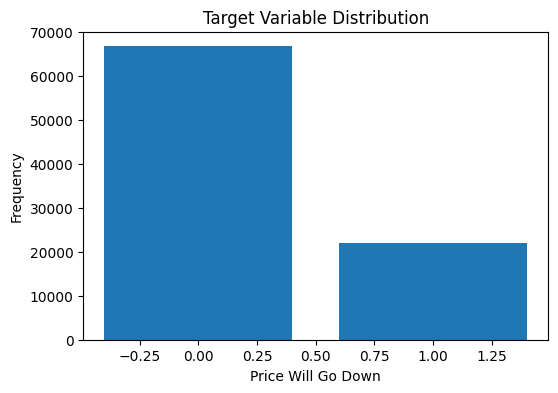

In [96]:

# Explore target variable distribution
distribution = y_train.value_counts()

# plot 
plt.figure(figsize=(6,4))
plt.bar(x=distribution.index, height=distribution.values)
plt.title('Target Variable Distribution')
plt.xlabel('Price Will Go Down')
plt.ylabel('Frequency')
plt.show()


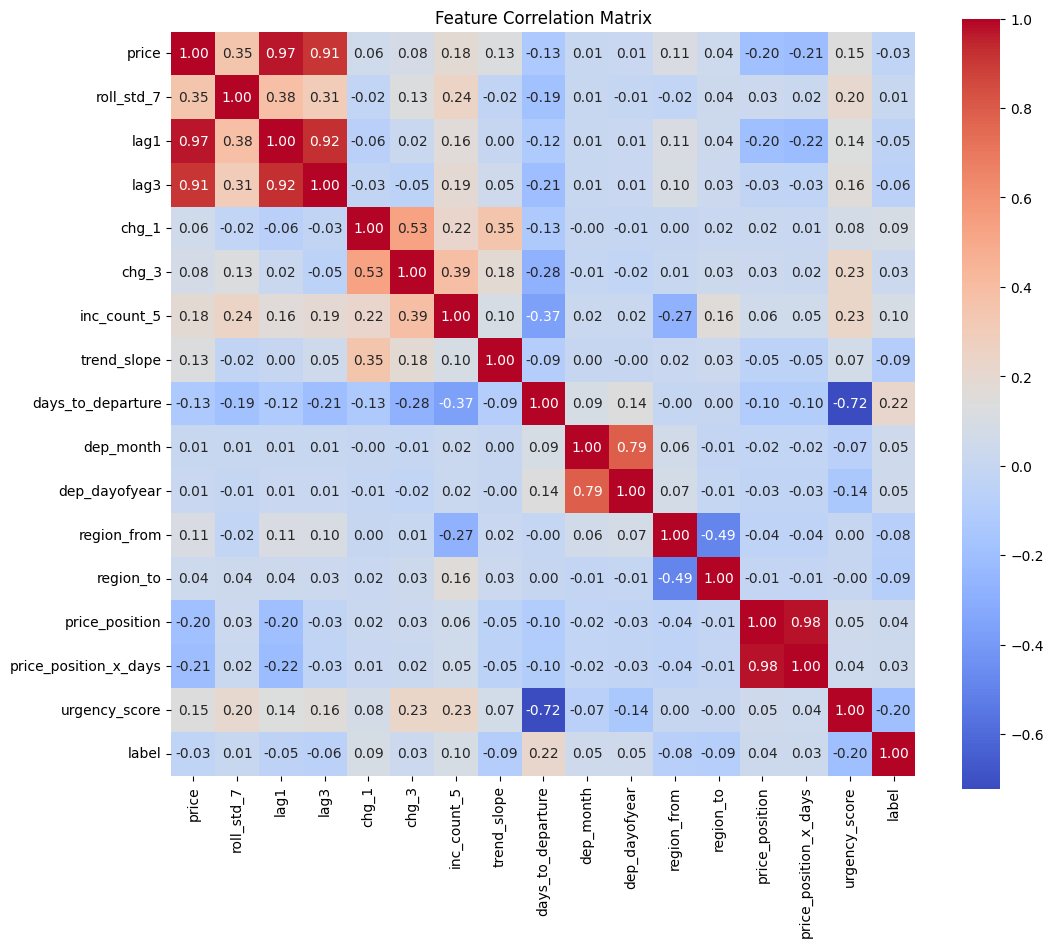

In [97]:
# correlation matrix

corr_df = X_train.copy()
corr_df['label'] = y_train

import seaborn as sns
plt.figure(figsize=(12, 10))
corr = corr_df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Feature Correlation Matrix')
plt.show()


In [70]:
colsto_drop = []
X_train_trimmed = X_train.drop(columns=colsto_drop, errors='ignore')
X_test_trimmed = X_test.drop(columns=colsto_drop, errors='ignore')

In [71]:
def filter_itin(data, flight_number = None, date_till = None):
    if flight_number:
        data = data[data['itinerary_id'].str.contains(f'{flight_number}-', na=False)]
    if date_till:
        print(date_till)
        data['departure_date'] = pd.to_datetime(data['departure_date'], errors='coerce')
        data = data[data['departure_date'] <= date_till]
    
    return data



def prices_for_the_route(route_prices: pd.DataFrame, route)-> pd.DataFrame:
    """
    Filter the DataFrame for a specific route, or for a specific flight if provided.
    :param df: DataFrame containing flight prices.
    :param route: Tuple containing the origin, destination, and optional flight .

    :return: smoothed DataFrame with normalized prices for the specified route.
    """

    
    if route[0] and route[1] != None:
        route_string = f"{route[0]}-{route[1]}"
        print(f"Filtering for route: {route_string}")
        route_prices = route_prices[route_prices['itinerary_id'].str.contains(route_string)]
        
    if route[2]:
        print(f"Filtering for flight: {route[2]}")
        route_prices = route_prices[route_prices['itinerary_id'].str.contains(route[2])]

        
    df = route_prices.copy()

    # Select only the relevant month
    print(f"Filtered DataFrame shape: {df.shape}")
    return df

def smooth_LOWESS(df: pd.DataFrame, to_normalize: bool = False) -> pd.DataFrame:

    """
    Smooth the prices in the DataFrame using LOWESS (Locally Weighted Scatterplot Smoothing).
    :param df: DataFrame containing flight prices.
    :param to_normalize: Boolean indicating whether to normalize the prices by the maximum price for each departure date.
    :return: smoothed DataFrame with normalized prices.
    """
    
   

    if to_normalize:

        # Normalize the price by the maximum price for each departure date - get rid of the price scale, only show relative price (removing the seasonal price level variation.)
        df['normalized_price'] = df.groupby('departure_date')['price'].transform(lambda x: x/ x.max())


        # Group by departure date and calculate the mean normalized price
        df = df.groupby('days_to_departure')['normalized_price'].mean().reset_index()

        filtered  = df[df['days_to_departure'] < 90]

        fr = filtered.copy()
        smoothed_fr = lowess(fr['normalized_price'], fr['days_to_departure'], frac=0.13)
    else:
        # Group by departure date and calculate the mean price
        df = df.groupby('days_to_departure')['price'].mean().reset_index()

        filtered  = df[df['days_to_departure'] < 90]

        fr = filtered.copy()
        smoothed_fr = lowess(fr['price'], fr['days_to_departure'], frac=0.13)

    return smoothed_fr


def smooth_prices_rolling(df: pd.DataFrame, to_normalize: bool = False, window: int = 3) -> pd.DataFrame:
    """
    Smooth prices using a rolling mean.
    :param df: DataFrame containing flight prices.
    :param to_normalize: Boolean indicating whether to normalize prices.
    :param window: Size of the rolling window (smaller = sharper).
    :return: DataFrame with smoothed prices.
    """
    if to_normalize:
        df['normalized_price'] = df.groupby('departure_date')['price'].transform(lambda x: x / x.max())
        df = df.groupby('days_to_departure')['normalized_price'].mean().reset_index()
        filtered = df[df['days_to_departure'] < 90]
        filtered['smoothed_price'] = filtered['normalized_price'].rolling(window=window, center=True).mean()
    else:
        df = df.groupby('days_to_departure')['price'].mean().reset_index()
        filtered = df[df['days_to_departure'] < 90]
        filtered['smoothed_price'] = filtered['price'].rolling(window=window, center=True).mean()


    return filtered[['days_to_departure', 'smoothed_price']].dropna()



In [72]:
# For specific date
specific = prices_for_the_route(df, (None, None, "LH200"))
data_specific = smooth_LOWESS(specific, to_normalize=True)

actual_data = pd.read_csv('test_data/LH200_actual.csv')
actual_data_np = actual_data['price'].iloc[::-1].to_numpy()
# normalize actual data
actual_data_np = actual_data_np / actual_data_np.max()


print(actual_data)


NameError: name 'df' is not defined

In [73]:

plt.figure(figsize=(10, 6))
plt.plot(data_specific[:, 0], data_specific[:, 1], color='steelblue', linestyle='-', linewidth=2 , label='Historical Avg (LOWESS)')
plt.plot(actual_data_np, color='orange', linestyle='--', linewidth=2 , label='Actual Price')

plt.title("Prices for Frankfurt to Berlin (LH200) flight")
plt.xlabel("Days to Departure")
plt.ylabel("Price (€)")
plt.gca().invert_xaxis()  # Invert x-axis to show days to departure in reverse order
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

NameError: name 'data_specific' is not defined

<Figure size 1000x600 with 0 Axes>

In [74]:
def modelfit(alg, X_train, y_train, useTrainCV=True, cv_folds=5, early_stopping_rounds=50):
    if useTrainCV:
        xgb_param = alg.get_xgb_params()
        dtrain = xgb.DMatrix(X_train, label=y_train)

        print("Running cross-validation...")
        cvresult = xgb.cv(
            xgb_param,
            dtrain,
            num_boost_round=alg.get_params()['n_estimators'],
            nfold=cv_folds,
            metrics='aucpr',
            early_stopping_rounds=early_stopping_rounds,
            seed=42,
            verbose_eval=True
        )
        best_n = cvresult.shape[0]
        print(f"Best n_estimators = {best_n}")
        alg.set_params(n_estimators=best_n)

    # Fit full model
    alg.fit(X_train, y_train, verbose=False)

    # Train metrics
    preds = alg.predict(X_train)
    pred_proba = alg.predict_proba(X_train)[:, 1]
    print("\nModel Report (train)")
    print("Accuracy      : %.4g" % metrics.accuracy_score(y_train, preds))
    print("ROC AUC       : %f" % metrics.roc_auc_score(y_train, pred_proba))
    print("F1 macro      : %f" % metrics.f1_score(y_train, preds, average="macro"))
    print("Precision macro: %f" % metrics.precision_score(y_train, preds, average="macro"))

    # Feature importance
    feat_imp = pd.Series(
        alg.get_booster().get_score(importance_type="gain")
    ).sort_values(ascending=False)
    feat_imp.plot(kind="bar", title="Feature Importances (gain)")
    plt.ylabel("Gain")
    plt.show()

    return alg



Model Report (train)
Accuracy      : 0.952
ROC AUC       : 0.988095
F1 macro      : 0.934417
Precision macro: 0.942078


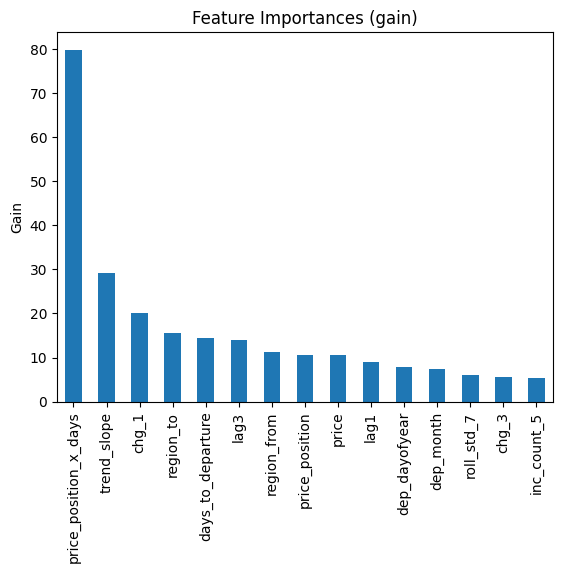

In [98]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=1000,        # big enough; CV will trim
    learning_rate=0.05,
    random_state=42,
    n_jobs=4
)

final_model = modelfit(
    xgb_clf,
    X_train, y_train,
    useTrainCV=False,           # run xgb.cv to find best n_estimators
    cv_folds=5,
    early_stopping_rounds=50    # stop if no AUC-PR improvement
)


In [106]:
from sklearn.calibration import CalibratedClassifierCV

cal = CalibratedClassifierCV(final_model, method="isotonic", cv=5)

cal.fit(X_train, y_train)
y_proba_cal = cal.predict_proba(X_test_trimmed)[:,1]



ValueError: feature_names mismatch: ['price', 'roll_std_7', 'lag1', 'lag3', 'chg_1', 'chg_3', 'inc_count_5', 'trend_slope', 'days_to_departure', 'dep_month', 'dep_dayofyear', 'region_from', 'region_to', 'price_position', 'price_position_x_days', 'urgency_score'] ['price', 'trend_slope_5', 'roll_std_7', 'lag1', 'lag3', 'chg_1', 'chg_3', 'inc_count_5', 'trend_slope', 'days_to_departure', 'dep_month', 'dep_dayofyear', 'region_from', 'region_to', 'price_position', 'price_position_x_days', 'urgency_score']
training data did not have the following fields: trend_slope_5

In [305]:
from sklearn.metrics import precision_score
scorer = make_scorer(precision_score, average="macro")


param_test1 = {
 'max_depth':range(1,8),
 'min_child_weight':range(1,8)
}


gsearch1 = GridSearchCV(estimator = xgb.XGBClassifier(learning_rate=0.1, n_estimators=1000,
    objective= 'binary:logistic'),
    param_grid = param_test1, scoring=scorer, n_jobs=4, cv=5)

gsearch1.fit(X_train, y_train)
gsearch1.cv_results_, gsearch1.best_params_, gsearch1.best_score_

({'mean_fit_time': array([ 3.78793259,  3.46531758,  3.4750999 ,  3.45446634,  4.14356403,
          3.66475677,  3.54793162,  4.722153  ,  4.74723649,  4.73767586,
          4.73278074,  4.82676177,  4.69053617,  4.76347055,  5.94156666,
          5.77971396,  5.63183603,  5.99320288,  5.82141318,  6.10529947,
          5.87761788,  7.05524368,  7.48596287,  6.88491831,  6.82797647,
          6.92464967,  6.81100736,  6.74944849,  8.41600847,  8.43165498,
          8.05379195,  8.08599534,  7.9613234 ,  8.35054488,  8.76923823,
         10.1988924 ,  9.96412134,  9.68856316, 10.00434957,  9.92302947,
          9.64456172,  9.69489126, 12.58442426, 12.92602248, 12.02617655,
         11.63171105, 11.58215551, 11.63982787,  9.91586127]),
  'std_fit_time': array([0.21159825, 0.04488915, 0.097057  , 0.07407736, 0.35654628,
         0.26928165, 0.06814972, 0.06310563, 0.15315159, 0.1064918 ,
         0.1366586 , 0.05238897, 0.11072679, 0.13950296, 0.11952989,
         0.21480691, 0.0897305 

In [179]:
param_test3 = {
 'gamma':[i/10.0 for i in range(0,5)]
}
gsearch3 = GridSearchCV(estimator = xgb.XGBClassifier( learning_rate =0.1, n_estimators=140, max_depth=3,
 min_child_weight=2, gamma=0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test3, scoring='balanced_accuracy',n_jobs=4, cv=5)
gsearch3.fit(X_train, y_train)
gsearch3.cv_results_, gsearch3.best_params_, gsearch3.best_score_

({'mean_fit_time': array([1.08083048, 1.09660454, 1.08853612, 1.07237372, 1.02152185]),
  'std_fit_time': array([0.02232799, 0.05641432, 0.06664732, 0.01657109, 0.2118336 ]),
  'mean_score_time': array([0.03299947, 0.0288837 , 0.03192005, 0.03084669, 0.02955251]),
  'std_score_time': array([0.0042268 , 0.00159926, 0.00207346, 0.00087549, 0.00705451]),
  'param_gamma': masked_array(data=[0.0, 0.1, 0.2, 0.3, 0.4],
               mask=[False, False, False, False, False],
         fill_value=1e+20),
  'params': [{'gamma': 0.0},
   {'gamma': 0.1},
   {'gamma': 0.2},
   {'gamma': 0.3},
   {'gamma': 0.4}],
  'split0_test_score': array([0.8411616 , 0.8411616 , 0.8411616 , 0.8411616 , 0.83946001]),
  'split1_test_score': array([0.8390432 , 0.83813615, 0.83813615, 0.83813615, 0.83813615]),
  'split2_test_score': array([0.81977083, 0.81977083, 0.81977083, 0.81977083, 0.81863982]),
  'split3_test_score': array([0.74519083, 0.74533014, 0.74560202, 0.74560202, 0.74560202]),
  'split4_test_score': ar

In [180]:
param_test4 = {
 'subsample':[i/10.0 for i in range(6,10)],
 'colsample_bytree':[i/10.0 for i in range(6,10)]
}
gsearch4 = GridSearchCV(estimator = xgb.XGBClassifier( learning_rate =0.1, n_estimators=140, max_depth=3,
 min_child_weight=2, gamma=0.0, subsample=0.8, colsample_bytree=0.8,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test4, scoring='balanced_accuracy',n_jobs=4, cv=5)
gsearch4.fit(X_train, y_train)
gsearch4.cv_results_, gsearch4.best_params_, gsearch4.best_score_

({'mean_fit_time': array([1.08523455, 1.06746316, 1.11698794, 1.25476475, 1.2754396 ,
         1.19838085, 1.11951089, 1.15677967, 1.14660597, 1.23076692,
         1.12349906, 1.10948114, 1.14996815, 1.15357261, 1.1273807 ,
         1.07339525]),
  'std_fit_time': array([0.00259797, 0.03275597, 0.07056102, 0.03923127, 0.05103517,
         0.09866697, 0.02064058, 0.02276002, 0.03086532, 0.06445597,
         0.01649519, 0.00864147, 0.00885447, 0.00760665, 0.01112521,
         0.04808215]),
  'mean_score_time': array([0.02833543, 0.02783718, 0.02874918, 0.03088551, 0.03378639,
         0.03518796, 0.03588657, 0.03755217, 0.03740325, 0.03859019,
         0.03634   , 0.0362287 , 0.03678222, 0.03731227, 0.03818989,
         0.03047543]),
  'std_score_time': array([0.002659  , 0.00184697, 0.00308883, 0.00198075, 0.00122118,
         0.00204151, 0.00123101, 0.00163139, 0.00081998, 0.00131072,
         0.00100331, 0.0012477 , 0.00119284, 0.00093502, 0.00104634,
         0.00708695]),
  'param_c

In [189]:
param_test5 = {
 'reg_alpha':[110,120,130,140,150,160]
}
gsearch5 = GridSearchCV(estimator = xgb.XGBClassifier( learning_rate =0.1, n_estimators=100, max_depth=3,
 min_child_weight=4, gamma=0.1, subsample=0.9, colsample_bytree=0.7,
 objective= 'binary:logistic', nthread=4, scale_pos_weight=1,seed=27), 
 param_grid = param_test5, scoring='balanced_accuracy',n_jobs=4, cv=5)
gsearch5.fit(X_train, y_train)
gsearch5.cv_results_, gsearch5.best_params_, gsearch5.best_score_

({'mean_fit_time': array([0.83847346, 0.78000813, 0.74757018, 0.74474277, 0.78402619,
         0.71513042]),
  'std_fit_time': array([0.02626261, 0.02405775, 0.01011929, 0.00562045, 0.00319414,
         0.09043422]),
  'mean_score_time': array([0.02266545, 0.02420092, 0.02161198, 0.02165389, 0.02476168,
         0.02087736]),
  'std_score_time': array([0.00213445, 0.00132973, 0.0007533 , 0.00102352, 0.00115001,
         0.00384475]),
  'param_reg_alpha': masked_array(data=[110, 120, 130, 140, 150, 160],
               mask=[False, False, False, False, False, False],
         fill_value=999999),
  'params': [{'reg_alpha': 110},
   {'reg_alpha': 120},
   {'reg_alpha': 130},
   {'reg_alpha': 140},
   {'reg_alpha': 150},
   {'reg_alpha': 160}],
  'split0_test_score': array([0.82808004, 0.82866214, 0.82446654, 0.82992066, 0.82395998,
         0.82540923]),
  'split1_test_score': array([0.83307287, 0.83205063, 0.83175167, 0.83169032, 0.83280686,
         0.82980415]),
  'split2_test_score': 

Threshold: 0.5
Predictions distribution:
  Class 0 (price won't drop): 18249
  Class 1 (price will drop): 3321

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94     16603
           1       0.92      0.61      0.74      4967

    accuracy                           0.90     21570
   macro avg       0.91      0.80      0.84     21570
weighted avg       0.90      0.90      0.89     21570



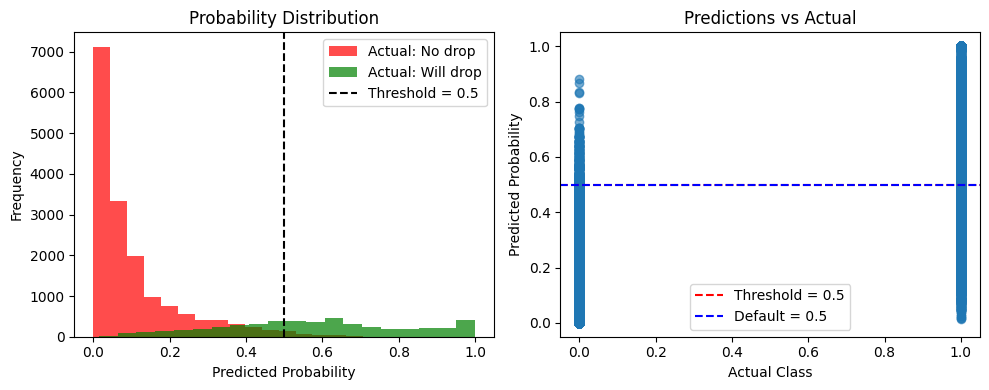


Predictions changed due to threshold: 0


In [107]:
def predict_with_custom_threshold(model, X_test, y_test, threshold=0.5, show_analysis=True):
    """
    Make predictions with custom threshold and show analysis.
    """
    # Get probabilities
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Apply threshold
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    if show_analysis:
        print(f"Threshold: {threshold}")
        print(f"Predictions distribution:")
        print(f"  Class 0 (price won't drop): {(y_pred == 0).sum()}")
        print(f"  Class 1 (price will drop): {(y_pred == 1).sum()}")
        print(f"\nClassification Report:")
        print(classification_report(y_test, y_pred))
        
        # Show probability distribution
        plt.figure(figsize=(10, 4))
        
        plt.subplot(1, 2, 1)
        plt.hist(y_pred_proba[y_test == 0], bins=20, alpha=0.7, label='Actual: No drop', color='red')
        plt.hist(y_pred_proba[y_test == 1], bins=20, alpha=0.7, label='Actual: Will drop', color='green')
        plt.axvline(x=threshold, color='black', linestyle='--', label=f'Threshold = {threshold}')
        plt.xlabel('Predicted Probability')
        plt.ylabel('Frequency')
        plt.title('Probability Distribution')
        plt.legend()
        
        plt.subplot(1, 2, 2)
        comparison_df = pd.DataFrame({
            'Actual': y_test.values, 
            'Predicted': y_pred,
            'Probability': y_pred_proba
        })
        
        # Show cases where we changed prediction due to threshold
        changed_predictions = comparison_df[
            ((comparison_df['Probability'] >= threshold) & (comparison_df['Probability'] < 0.5)) |
            ((comparison_df['Probability'] < threshold) & (comparison_df['Probability'] >= 0.5))
        ]
        
        plt.scatter(comparison_df['Actual'], comparison_df['Probability'], alpha=0.6)
        plt.axhline(y=threshold, color='red', linestyle='--', label=f'Threshold = {threshold}')
        plt.axhline(y=0.5, color='blue', linestyle='--', label='Default = 0.5')
        plt.xlabel('Actual Class')
        plt.ylabel('Predicted Probability')
        plt.title('Predictions vs Actual')
        plt.legend()
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nPredictions changed due to threshold: {len(changed_predictions)}")
    
    return y_pred, y_pred_proba

# Usage
y_pred_custom, y_proba = predict_with_custom_threshold(cal, X_test, y_test, threshold=0.5)

## Test case

In [108]:
# Predicting test flight

def test_flight(date_time, src, dst, flight_number=None, distance=None, path=None):
    date, time = date_time.split(' ')
    date = datetime.strptime(date, '%Y-%m-%d')
    print(date)
    time = datetime.strptime(time, '%H:%M').time()
    # Example: create a test dictionary for a single flight
    flight_params = {
        'itinerary_id': f'{flight_number}-{date.strftime("%Y%m%d")}-{src}-{dst}',
        'flight_number': flight_number,
        'src': src,
        'dst': dst,
        'dep_month': date.month,
        'dep_dayofyear': date.timetuple().tm_yday,
        'is_weekend': 0 if date.weekday() <= 4 else 1,  # Saturday or Sunday
        'distance': distance,  # example value, adjust as needed
        'region_from': encoders['region_from'].transform(['Western'])[0],
        'region_to': encoders['region_to'].transform(['Western'])[0],
    }
    


    test_flight = pd.read_csv(path)
    # Convert timestamp to datetime
    test_flight['timestamp'] = pd.to_datetime(test_flight['timestamp'], unit='ms')
    test_flight['timestamp'] = pd.to_datetime(test_flight['timestamp'].dt.date)
    # Days to departure
    test_flight['Date'] = (date - test_flight['timestamp']).dt.days
    test_flight['Price'] = test_flight['price']

    test_rows = []
    for row in test_flight.itertuples(index=False):
        ft = flight_params.copy()
        ft['days_to_departure'] = row.Date
        ft['price'] = row.Price
        test_rows.append(ft)

    # Create DataFrame
    test_df = pd.DataFrame(test_rows)



    return test_df

In [125]:
test_flight1 = test_flight('2025-09-06 20:15', 'FRA', 'BER', 'FR411', distance=430, path = 'test_data/LH200_actual.csv')


test_df = price_will_go_down(test_flight1, train_data, 150, 90)

X_test_flight, y_test_flight = prepare_features_and_target(test_df, 'label')


2025-09-06 00:00:00
Using provided sample_max: 150, sample_min: 90
0     60
1     60
2     60
3     60
4     60
      ..
56    60
57    60
58    60
59    60
60    60
Name: price_range, Length: 61, dtype: int64


C:\Users\pinyc\AppData\Local\Temp\ipykernel_6608\4138027230.py:79: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_6608\4138027230.py:118: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('itinerary_id').apply(roll).reset_index(drop=True)


In [126]:
y_test_pred_proba = final_model.predict_proba(X_test_flight)[:, 1]
print(f"F1 score Score: {f1_score(y_test_flight,  (y_test_pred_proba >= 0.3).astype(int)):.4f}")

    
comparison_df = pd.DataFrame({
    'Actual': y_test_flight.values,
    'Predicted': (y_test_pred_proba >= 0.3).astype(int),
    'Probability': y_test_pred_proba*100,
    'days_to_departure': X_test_flight['days_to_departure'],
    'price': X_test_flight['price'],
})

print(comparison_df.head(60))

F1 score Score: 0.8000
    Actual  Predicted  Probability  days_to_departure  price
1        1          1    59.107285                 60     98
2        1          1    59.107285                 59     98
3        1          1    56.005596                 58     98
4        1          1    56.005596                 57     98
5        1          1    78.771431                 56     98
6        0          0    19.570026                 55     92
7        0          1    40.515728                 54     92
8        0          1    40.515728                 53     92
9        0          1    37.744274                 52     92
10       1          1    76.711807                 51     98
11       1          1    37.784969                 50     98
12       1          1    37.784969                 49     98
13       1          1    35.535557                 48     98
14       1          1    31.172367                 47     98
15       1          1    30.343601                 46     98
1

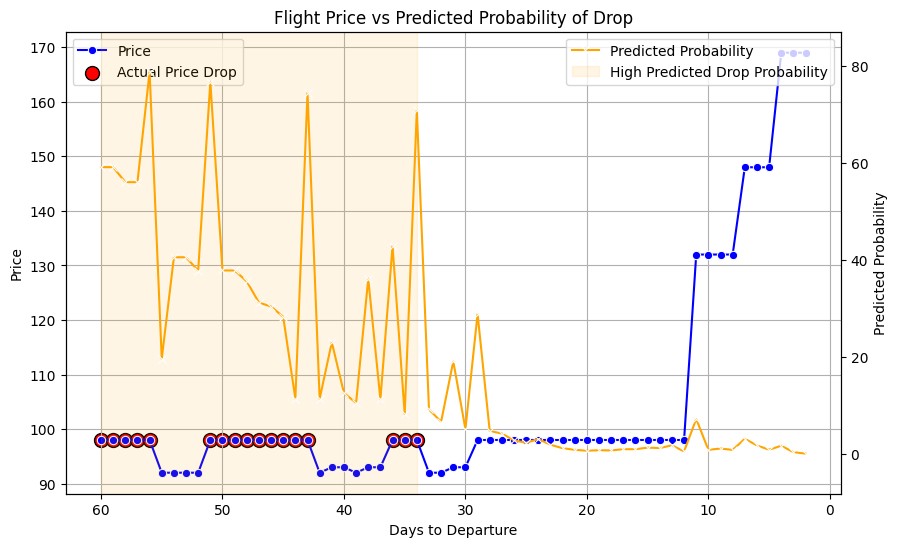

In [127]:

import seaborn as sns

# Price line
plt.figure(figsize=(10, 6))

sns.lineplot(x="days_to_departure", y="price", data=comparison_df, marker="o", label="Price", color="blue")

# Secondary axis for probability
ax1 = plt.gca()
ax2 = ax1.twinx()
sns.lineplot(x="days_to_departure", y="Probability", data=comparison_df, marker="x", label="Predicted Probability", color="orange", ax=ax2)
ax2.set_ylabel("Predicted Probability")

# Highlight actual price drops
drops = comparison_df[comparison_df["Actual"] == 1]
ax1.scatter(drops["days_to_departure"], drops["price"], color='red', s=100, edgecolor='black', label="Actual Price Drop")

# Highlight high probability of drop (>0.5)
high_prob = comparison_df[comparison_df["Probability"] > 50]
ax2.fill_between(high_prob["days_to_departure"], 0, 1, color='orange', alpha=0.1, transform=ax2.get_xaxis_transform(), label="High Predicted Drop Probability")

# Labels, title, grid
ax1.set_xlabel("Days to Departure")
ax1.set_ylabel("Price")
ax1.invert_xaxis()  # decreasing days to departure
plt.title("Flight Price vs Predicted Probability of Drop")
ax1.grid(True)
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

In [ ]:
test_flight1 = test_flight('2025-09-07 15:45', 'JFK', 'FRA', 'LH410', distance=430, path='test_data/LH401_actual.csv')


test_df = price_will_go_down(test_flight1,train_data)

X_test_flight, y_test_flight = prepare_features_and_target(test_df, 'label')


y_test_pred_proba = cal.predict_proba(X_test_flight_trimmed)[:, 1]
print(f"F1 Score: {f1_score(y_test_flight, (y_test_pred_proba >= 0.1).astype(int)):.4f}")

    
comparison_df = pd.DataFrame({
    'Actual': y_test_flight.values,
    'Predicted': (y_test_pred_proba >= 0.3).astype(int),
    'Probability': y_test_pred_proba*100,
    'days_to_departure': X_test_flight['days_to_departure'],
    'price': X_test_flight['price'],
})

print(comparison_df.head(60))


2025-09-07 00:00:00
0     240
1     240
2     240
3     240
4     240
     ... 
56    240
57    240
58    240
59    240
60    240
Name: price_range, Length: 61, dtype: int64
F1 Score: 0.2174
    Actual  Predicted  Probability  days_to_departure  price
5        0          1    58.036193                 55    408
6        0          1    31.528603                 54    409
7        0          1    38.298179                 53    411
8        0          1    39.534218                 52    410
9        0          1    33.318233                 51    410
10       0          1    53.649863                 50    410
11       0          1    44.860823                 49    410
12       0          1    45.022684                 48    506
13       0          1    43.222747                 47    503
14       0          1    41.094192                 46    501
15       0          0    28.238651                 45    508
16       0          0    29.273692                 44    501
17       0      

C:\Users\pinyc\AppData\Local\Temp\ipykernel_6608\4293829910.py:78: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  g['trend_slope'] = np.gradient(p.fillna(method='ffill').fillna(method='bfill'))
C:\Users\pinyc\AppData\Local\Temp\ipykernel_6608\4293829910.py:117: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('itinerary_id').apply(roll).reset_index(drop=True)


In [87]:
X_test_flight.head(60)

,price,trend_slope_5,roll_std_7,lag1,lag3,chg_1,chg_3,inc_count_5,trend_slope,days_to_departure,dep_month,dep_dayofyear,region_from,region_to,price_position,price_position_x_days,urgency_score
5,408,0.4,0.836660,408.0,407.0,0.000000,0.002457,2,0.5,55,9,250,7,7,-0.425000,-23.375000,0.017857
6,409,0.5,0.816497,408.0,408.0,0.002451,0.002451,3,1.5,54,9,250,7,7,-0.420833,-22.725000,0.018182
7,411,0.4,0.975900,409.0,408.0,0.004890,0.007353,3,0.5,53,9,250,7,7,-0.412500,-21.862500,0.018519
8,410,0.7,1.573592,411.0,408.0,-0.002433,0.004902,2,-0.5,52,9,250,7,7,-0.416667,-21.666667,0.018868
9,410,0.7,1.380131,410.0,409.0,0.000000,0.002445,2,0.0,51,9,250,7,7,-0.416667,-21.250000,0.019231
10,410,0.5,1.214986,410.0,411.0,0.000000,-0.002433,2,0.0,50,9,250,7,7,-0.416667,-20.833333,0.019608
11,410,0.1,1.133893,410.0,410.0,0.000000,0.000000,1,48.0,49,9,250,7,7,-0.416667,-20.416667,0.020000
12,506,-0.2,0.951190,410.0,410.0,0.234146,0.234146,1,46.5,48,9,250,7,7,-0.016667,-0.800000,0.020408
13,503,19.2,36.289182,506.0,410.0,-0.005929,0.226829,1,-2.5,47,9,250,7,7,-0.029167,-1.370833,0.020833
14,501,28.2,46.023286,503.0,410.0,-0.003976,0.221951,1,2.5,46,9,250,7,7,-0.037500,-1.725000,0.021277
